# 05 — Phúc: mô hình tuần 5 trên 12 feature hiện có

Mục tiêu: so sánh LR thường/cân bằng, RBF SVM, MLP và HistGradientBoosting trước khi Hy bàn giao brand features.

**Trạng thái phạm vi:** chỉ lexical 12 feature; chưa có ablation brand, chưa chốt Teacher, chưa KD/mobile. AP làm chính đã được Phúc xác nhận trước khi xem kết quả; threshold 0,5 cố định; official validation bổ sung, official test chưa chấm.

Đọc thêm [giao thức tuần 5](../docs/project/week5_protocol.md). E1 được giữ nguyên, đầu ra tuần này có tiền tố `05_`.

## 0. Môi trường và đường dẫn

Chọn kernel **PhishGuardVN (.venv)**. Tạo handoff bằng 01 → 03 → 02 trước. Notebook mặc định đọc kết quả đã lưu; chỉ bật `RUN_TRAINING` khi chủ động chạy lại thí nghiệm.

In [1]:
from pathlib import Path
import sys
import tomllib
import json

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents)
                     if (p / "pyproject.toml").is_file()
                     and (p / "src/phishguard_vn").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Mở notebook bên trong repo PhishGuardVN.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
import joblib
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from phishguard_vn.modeling import load_baseline_inputs, predict_url
from phishguard_vn.experiments import run_experiments
from phishguard_vn.week5_reporting import save_week5_results

CONFIG_PATH = PROJECT_ROOT / "configs/e2_models.toml"
with CONFIG_PATH.open("rb") as handle:
    CONFIG = tomllib.load(handle)
print("Project:", PROJECT_ROOT)
print("Feature set:", CONFIG["experiment"]["feature_set"])
print("Tiêu chí chính:", CONFIG["evaluation"]["primary_metric"])


Project: D:\PhishGuardVN
Feature set: lexical_12
Tiêu chí chính: average_precision


## 1. Kiểm tra đầu vào

X chỉ gồm ID + 12 feature của Hy. Nhãn/tier/split/domain là metadata riêng. Folds giữ nguyên theo ID do Hưng bàn giao; không tự chia ngẫu nhiên lại hoặc thêm source vào X.

In [2]:
features, targets, folds = load_baseline_inputs(PROJECT_ROOT)
print("X:", features.shape, "| Metadata:", targets.shape, "| Train folds:", len(folds))
display(features.head(3))
display(targets.groupby(["split", "label"]).size().unstack(fill_value=0))


X: (18995, 13) | Metadata: (18997, 5) | Train folds: 13078


,id,url_len,dom_len,is_ip,subdom_cnt,letter_cnt,digit_cnt,dot_cnt,dash_cnt,under_cnt,slash_cnt,entropy,path_len
0,75a477a7-aed5-5906-8d6c-e1fc739ef9fd,23.0,23.0,0.0,0.0,21.0,0.0,1.0,1.0,0.0,0.0,3.882045,0.0
1,939ebc8f-c54d-50f2-84e7-f02ed5a6aca5,17.0,17.0,0.0,0.0,15.0,0.0,1.0,1.0,0.0,0.0,3.381580,0.0
2,e3042cd5-fbb9-592c-a8af-0f9c61197b4d,16.0,16.0,0.0,0.0,11.0,4.0,1.0,0.0,0.0,0.0,3.452820,0.0


label,benign,phishing
split,,
test,3845,487
train,11004,2076
val,1561,24


## 2. Chạy thực nghiệm — tùy chọn

Outer folds để đánh giá; inner group folds chỉ ở phần được học để chọn cấu hình bằng AP. SVM có group calibration nằm trong mỗi lần fit. Scaler nằm trong base pipeline. MLP/boosting không dùng random validation early stopping.

Chạy mặc định từ terminal: `python scripts/train_week5.py`. Đổi cờ dưới thành `True` để chạy từ notebook; thao tác này chỉ ghi lại output tuần 5.

In [3]:
RUN_TRAINING = False
if RUN_TRAINING:
    with threadpool_limits(limits=1):
        result = run_experiments(features, targets, folds, CONFIG, progress=print)
        result["runtime"] = {"threadpool_limit": 1, "parallel_search": False}
        artifact_path = save_week5_results(result, CONFIG, PROJECT_ROOT, CONFIG_PATH)
    print("Đã lưu:", artifact_path)
else:
    print("Đọc kết quả đã lưu; không train lại trong notebook.")


Đọc kết quả đã lưu; không train lại trong notebook.


## 3. Kết quả outer CV

Bảng summary là mean/std qua các folds, khác pooled OOF. Chọn family bằng AP, không chọn theo official validation. Điểm của family thắng đã tham gia chọn family nên chưa phải ước lượng cuối cùng không thiên lệch của hệ thống được chọn.

In [4]:
TABLES = PROJECT_ROOT / "reports/tables"
required = ["05_cv_summary.csv", "05_cv_metrics.csv", "05_run_metadata.json"]
missing = [name for name in required if not (TABLES / name).is_file()]
if missing:
    raise FileNotFoundError("Chạy scripts/train_week5.py trước. Thiếu: " + ", ".join(missing))
summary = pd.read_csv(TABLES / "05_cv_summary.csv")
cv_metrics = pd.read_csv(TABLES / "05_cv_metrics.csv")
metadata = json.loads((TABLES / "05_run_metadata.json").read_text(encoding="utf-8"))
display(summary)
display(cv_metrics)
print("Ứng viên lexical-only:", metadata["selected_model"])
print("Official test:", metadata["scope"].get("test_evaluated", "xem scope"))


,model,accuracy_mean,accuracy_std,precision_phishing_mean,precision_phishing_std,recall_phishing_mean,recall_phishing_std,f1_phishing_mean,f1_phishing_std,pr_auc_mean,pr_auc_std,false_positive_rate_mean,false_positive_rate_std
0,logistic_regression,0.873911,0.004759,0.729997,0.029375,0.326929,0.045412,0.449986,0.043073,0.594173,0.015811,0.022992,0.005331
1,logistic_regression_balanced,0.725877,0.014879,0.344914,0.012513,0.807131,0.008863,0.483148,0.010705,0.557744,0.015502,0.289440,0.019357
2,svm_rbf,0.895015,0.003648,0.839578,0.037857,0.419008,0.020630,0.558525,0.017210,0.642642,0.031804,0.015267,0.004659
3,mlp,0.898226,0.003897,0.798302,0.024278,0.481222,0.048225,0.598947,0.033277,0.699200,0.014049,0.023173,0.005308
4,hist_gradient_boosting,0.900979,0.003661,0.819157,0.003361,0.482176,0.032179,0.606561,0.024645,0.697899,0.022626,0.020084,0.001774


,model,evaluation_partition,fold_id,candidate_id,threshold,fit_seconds,n_rows,n_benign,n_phishing,accuracy,precision_phishing,recall_phishing,f1_phishing,pr_auc,pr_auc_definition,false_positive_rate,tn,fp,fn,tp
0,logistic_regression,group_cv,0,logistic_regression_00,0.5,0.054044,4359,3668,691,0.879330,0.744807,0.363242,0.488327,0.612305,average_precision,0.023446,3582,86,440,251
1,logistic_regression,group_cv,1,logistic_regression_00,0.5,0.014126,4359,3668,691,0.871989,0.696165,0.341534,0.458252,0.583263,average_precision,0.028081,3565,103,455,236
2,logistic_regression,group_cv,2,logistic_regression_00,0.5,0.013315,4360,3668,692,0.870413,0.749020,0.276012,0.403379,0.586950,average_precision,0.017448,3604,64,501,191
3,logistic_regression_balanced,group_cv,0,logistic_regression_balanced_00,0.5,0.015313,4359,3668,691,0.725855,0.344252,0.806078,0.482460,0.558739,average_precision,0.289258,2607,1061,134,557
4,logistic_regression_balanced,group_cv,1,logistic_regression_balanced_00,0.5,0.012397,4359,3668,691,0.740766,0.357745,0.798842,0.494181,0.541768,average_precision,0.270174,2677,991,139,552
5,logistic_regression_balanced,group_cv,2,logistic_regression_balanced_00,0.5,0.012105,4360,3668,692,0.711009,0.332744,0.816474,0.472803,0.572724,average_precision,0.308888,2535,1133,127,565
6,svm_rbf,group_cv,0,svm_rbf_00,0.5,1.504723,4359,3668,691,0.899059,0.879154,0.421129,0.569472,0.672844,average_precision,0.010905,3628,40,400,291
7,svm_rbf,group_cv,1,svm_rbf_01,0.5,1.519569,4359,3668,691,0.894012,0.803714,0.438495,0.567416,0.609447,average_precision,0.020174,3594,74,388,303
8,svm_rbf,group_cv,2,svm_rbf_01,0.5,1.385076,4360,3668,692,0.891972,0.835866,0.397399,0.538688,0.645635,average_precision,0.014722,3614,54,417,275
9,mlp,group_cv,0,mlp_00,0.5,3.109919,4359,3668,691,0.902271,0.795100,0.516643,0.626316,0.715295,average_precision,0.025082,3576,92,334,357


Ứng viên lexical-only: mlp
Official test: False


## 4. Kiểm tra việc chọn cấu hình và convergence

Lựa chọn `outer_fold = -1` dành cho lần fit toàn train sau CV. Kiểm tra tham số, inner AP, fit log và split audit; không chỉ nhìn bảng summary. Hyperparameters của các outer folds có thể khác nhau vì chúng được chọn từ những tập train khác nhau.

In [5]:
selections = pd.read_csv(TABLES / "05_selections.csv")
fit_log = pd.read_csv(TABLES / "05_fit_log.csv")
split_audit = pd.read_csv(TABLES / "05_split_audit.csv")
display(selections)
display(fit_log.head(12))
display(split_audit.head(12))


,model,outer_fold,candidate_id,parameters_json,mean_inner_ap,status
0,logistic_regression,0,logistic_regression_00,"{""C"": 1.0, ""class_weight"": ""none"", ""max_iter"":...",NaN,fixed_config
1,logistic_regression,1,logistic_regression_00,"{""C"": 1.0, ""class_weight"": ""none"", ""max_iter"":...",NaN,fixed_config
2,logistic_regression,2,logistic_regression_00,"{""C"": 1.0, ""class_weight"": ""none"", ""max_iter"":...",NaN,fixed_config
3,logistic_regression_balanced,0,logistic_regression_balanced_00,"{""C"": 1.0, ""class_weight"": ""balanced"", ""max_it...",NaN,fixed_config
4,logistic_regression_balanced,1,logistic_regression_balanced_00,"{""C"": 1.0, ""class_weight"": ""balanced"", ""max_it...",NaN,fixed_config
5,logistic_regression_balanced,2,logistic_regression_balanced_00,"{""C"": 1.0, ""class_weight"": ""balanced"", ""max_it...",NaN,fixed_config
6,svm_rbf,0,svm_rbf_00,"{""C"": 0.5, ""class_weight"": ""none"", ""gamma"": ""s...",0.627400,selected_by_inner_ap
7,svm_rbf,1,svm_rbf_01,"{""C"": 2.0, ""class_weight"": ""none"", ""gamma"": ""s...",0.663913,selected_by_inner_ap
8,svm_rbf,2,svm_rbf_01,"{""C"": 2.0, ""class_weight"": ""none"", ""gamma"": ""s...",0.624726,selected_by_inner_ap
9,mlp,0,mlp_00,"{""alpha"": 0.001, ""hidden_layer_sizes"": [32], ""...",0.674274,selected_by_inner_ap


,model,outer_fold,inner_fold,candidate_id,phase,fit_seconds,converged,warnings,error,status
0,logistic_regression,0,-1,logistic_regression_00,outer_refit,0.054044,True,[],NaN,ok
1,logistic_regression,1,-1,logistic_regression_00,outer_refit,0.014126,True,[],NaN,ok
2,logistic_regression,2,-1,logistic_regression_00,outer_refit,0.013315,True,[],NaN,ok
3,logistic_regression_balanced,0,-1,logistic_regression_balanced_00,outer_refit,0.015313,True,[],NaN,ok
4,logistic_regression_balanced,1,-1,logistic_regression_balanced_00,outer_refit,0.012397,True,[],NaN,ok
5,logistic_regression_balanced,2,-1,logistic_regression_balanced_00,outer_refit,0.012105,True,[],NaN,ok
6,svm_rbf,0,0,svm_rbf_00,inner,0.412557,True,"[""The `probability` parameter was deprecated i...",NaN,ok
7,svm_rbf,0,1,svm_rbf_00,inner,0.387395,True,"[""The `probability` parameter was deprecated i...",NaN,ok
8,svm_rbf,0,0,svm_rbf_01,inner,0.404485,True,"[""The `probability` parameter was deprecated i...",NaN,ok
9,svm_rbf,0,1,svm_rbf_01,inner,0.431725,True,"[""The `probability` parameter was deprecated i...",NaN,ok


,model,outer_fold,kind,phase,inner_fold,candidate_id,split_id,fitting_rows,held_rows,fitting_phishing,held_phishing,fitting_groups,held_groups,overlap_groups,fitting_ids_sha256,held_ids_sha256
0,all,0,outer_evaluation,outer,-1,all,0,8719,4359,1383,691,5897,2938,0,9293a0db58db31c33ad75444eaa89cde10adc541d211f3...,bb44209eab2405fb2391da47479f3d6016629a951bdf88...
1,all,1,outer_evaluation,outer,-1,all,1,8719,4359,1383,691,5888,2947,0,9a6646dde7bebce99bb876fe714a57cbeaa18150090078...,1b68df822f9fea3e67ce2be1f15e4ef1e368b9e0e36d53...
2,all,2,outer_evaluation,outer,-1,all,2,8718,4360,1382,692,5885,2950,0,2f88f1d159746a8388027a595e09d29837fc6d446d92c0...,4fa168f676caa97fd6b0c0e7b557b830245720d991199a...
3,svm_rbf,0,inner_selection,inner,0,all,0,4360,4359,692,691,2953,2944,0,362a1fa5c7f1abacff8b0e9f242546a0f7690400b30390...,ccee61a823db0cb58ea416cae9baa10baa1aa45dc3a1ec...
4,svm_rbf,0,inner_selection,inner,1,all,1,4359,4360,691,692,2944,2953,0,ccee61a823db0cb58ea416cae9baa10baa1aa45dc3a1ec...,362a1fa5c7f1abacff8b0e9f242546a0f7690400b30390...
5,svm_rbf,0,calibration,inner,0,svm_rbf_00,0,2180,2180,346,346,1476,1477,0,78189b1827cb7a3a922a4e7324827ebb4d21d341117802...,702251e84901037166c3958c56747250937fb755d4575a...
6,svm_rbf,0,calibration,inner,0,svm_rbf_00,1,2180,2180,346,346,1477,1476,0,702251e84901037166c3958c56747250937fb755d4575a...,78189b1827cb7a3a922a4e7324827ebb4d21d341117802...
7,svm_rbf,0,calibration,inner,1,svm_rbf_00,0,2179,2180,345,346,1468,1476,0,94ad1b8549714f43408aa7d48ea09d2e6faa0dcdf80534...,ac7a2080b538645a2517e3f2d0f7dc0129ade0b133e3f6...
8,svm_rbf,0,calibration,inner,1,svm_rbf_00,1,2180,2179,346,345,1476,1468,0,ac7a2080b538645a2517e3f2d0f7dc0129ade0b133e3f6...,94ad1b8549714f43408aa7d48ea09d2e6faa0dcdf80534...
9,svm_rbf,0,calibration,inner,0,svm_rbf_01,0,2180,2180,346,346,1476,1477,0,78189b1827cb7a3a922a4e7324827ebb4d21d341117802...,702251e84901037166c3958c56747250937fb755d4575a...


## 5. Validation bổ sung và đối chứng E1

Cùng threshold 0,5 không bảo đảm các thuật toán có cùng FPR/Recall. Đọc cả precision, recall, FPR và số FP/FN; không đổi winner/threshold vì nhìn validation. E1 chọn bằng F1, tuần này AP làm chính; không thay đổi E1 để khớp winner mới.

In [6]:
validation = pd.read_csv(TABLES / "05_validation_metrics.csv")
display(validation)
e1 = pd.read_csv(TABLES / "04_cv_summary.csv")
comparison = e1.merge(summary, on="model", suffixes=("_e1", "_week5"))
if not comparison.empty:
    comparison["delta_ap"] = comparison["pr_auc_mean_week5"] - comparison["pr_auc_mean_e1"]
    comparison["delta_f1"] = comparison["f1_phishing_mean_week5"] - comparison["f1_phishing_mean_e1"]
    display(comparison[["model", "delta_ap", "delta_f1"]])


,model,evaluation_partition,candidate_id,threshold,n_rows,n_benign,n_phishing,accuracy,precision_phishing,recall_phishing,f1_phishing,pr_auc,pr_auc_definition,false_positive_rate,tn,fp,fn,tp
0,logistic_regression,official_validation,logistic_regression_00,0.5,1585,1561,24,0.970347,0.255319,0.500000,0.338028,0.293308,average_precision,0.022422,1526,35,12,12
1,logistic_regression_balanced,official_validation,logistic_regression_balanced_00,0.5,1585,1561,24,0.591798,0.034380,0.958333,0.066378,0.274431,average_precision,0.413837,915,646,1,23
2,svm_rbf,official_validation,svm_rbf_00,0.5,1585,1561,24,0.979811,0.346154,0.375000,0.360000,0.263879,average_precision,0.010890,1544,17,15,9
3,mlp,official_validation,mlp_01,0.5,1585,1561,24,0.969085,0.244898,0.500000,0.328767,0.431387,average_precision,0.023703,1524,37,12,12
4,hist_gradient_boosting,official_validation,hist_gradient_boosting_00,0.5,1585,1561,24,0.976025,0.325000,0.541667,0.406250,0.433845,average_precision,0.017297,1534,27,11,13


,model,delta_ap,delta_f1
0,logistic_regression,0.0,0.0
1,logistic_regression_balanced,0.0,0.0


## 6. Biểu đồ và bàn giao cho Hưng

Đường PR dùng OOF gộp, không thay thế AP trung bình từng fold. Predictions đầy đủ ở `data/interim/05_cv_predictions.csv` và `05_validation_predictions.csv`, giữ ID để phân tích nguồn/fold/tier. Hưng sẽ kiểm tra lỗi thực tế và robustness; notebook này không tạo nhận xét thủ công giả.

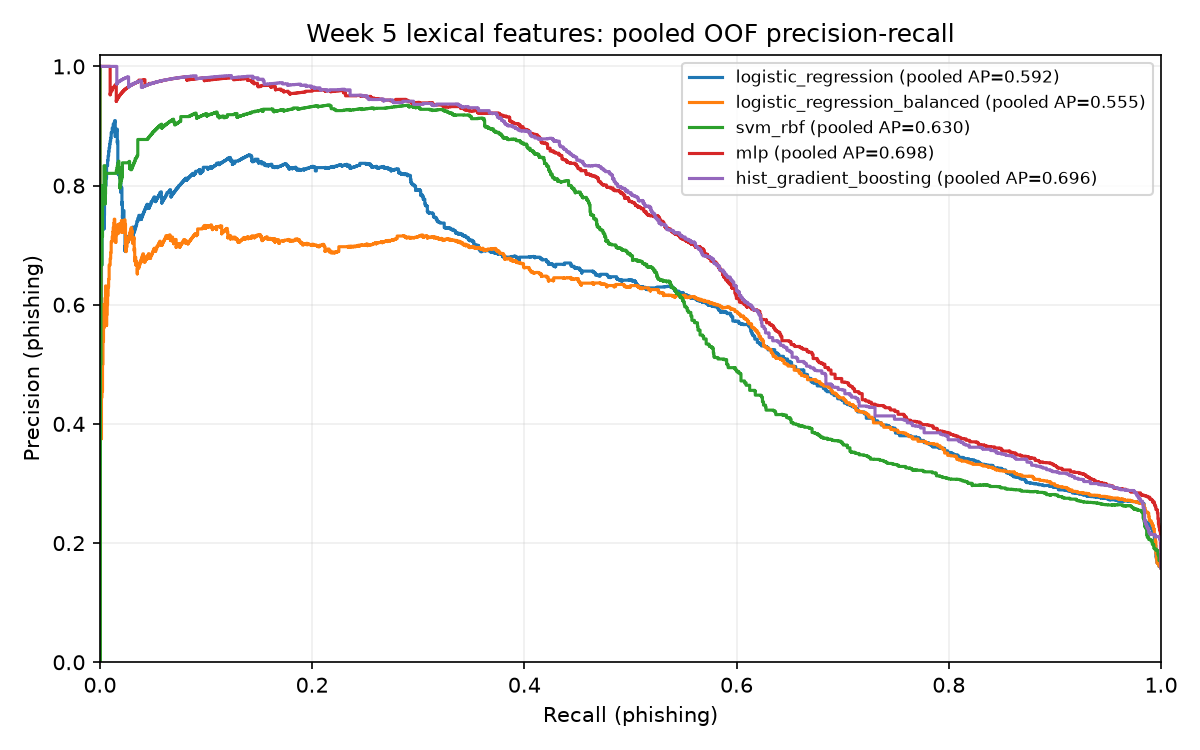

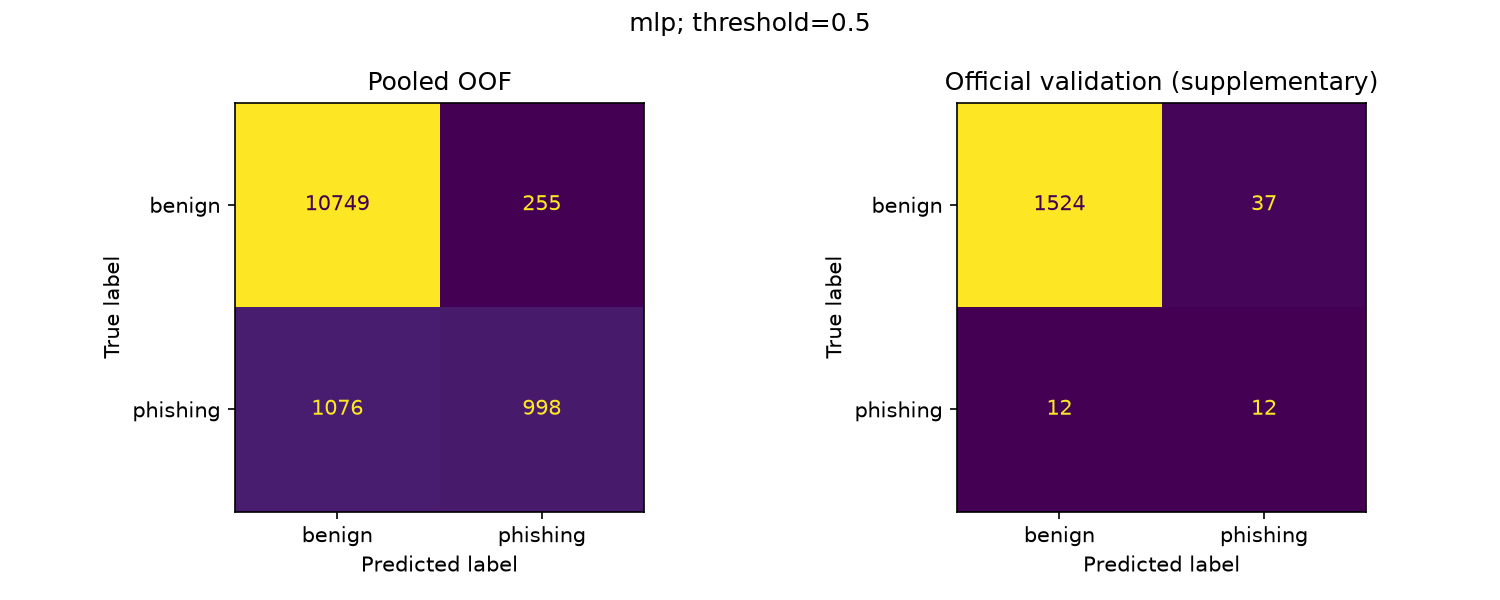

In [7]:
display(Image(filename=str(PROJECT_ROOT / "reports/figures/05_precision_recall_cv.png")))
display(Image(filename=str(PROJECT_ROOT / "reports/figures/05_confusion_matrices.png")))


## 7. Load model và thử URL mới

Đây là kiểm tra kỹ thuật luồng parser → 12 feature → model đã học. Ví dụ không chứng minh chất lượng thực tế. Score chưa phải xác suất nguy cơ đã được xác minh/hiệu chuẩn cho môi trường triển khai.

In [8]:
bundle = joblib.load(PROJECT_ROOT / "models/week5_lexical_models.joblib")
selected = bundle["selected_model"]
with threadpool_limits(limits=1):
    prediction = predict_url("https://example.com/a", bundle["estimators"][selected],
                             bundle["feature_names"], bundle["decision_threshold"])
print("Mô hình:", selected)
print(prediction)


Mô hình:

 mlp
{'label': 'phishing', 'score': 0.6072624063173977, 'threshold': 0.5, 'score_definition': 'uncalibrated model predict_proba for phishing'}


## 8. Phần chưa thực hiện

- Chờ Hy bàn giao brand dictionary/spec, feature version/hash và X theo ID.
- Sau đó mới chạy ablation 12 vs 12+brand trên cùng tập mẫu/folds đủ điều kiện.
- Cùng Hưng/Khiêm đọc lỗi, độ ổn định và source bias.
- Chưa chốt Teacher cuối cùng; chưa train Student/KD hoặc triển khai mobile.

Báo cáo đã đo nằm ở [week5_models.md](../reports/week5_models.md); source/config/inputs/model hashes ở `reports/tables/05_run_metadata.json`.